# NCA Sentinel-2 monthly medians | fixed-site observatory

**Purpose.** Load annual GEE table exports (2018–2026), map all field locations in EPSG:26911, summarize observation coverage and monthly spectral medians, and inspect spectral trajectories at fixed locations. The **field year** identifies when vegetation was monitored; the **spectral year** identifies the remotely sensed observations. Spectral changes in unmonitored years are **not measured vegetation transitions**.

**Folder convention** (relative to this notebook):

```text
./NCA_S2_MonthlyMedians_SiteObservatory.ipynb
./data/monthly_medians/NCA_S2_monthly_medians_sites_2018.csv
./data/monthly_medians/NCA_S2_monthly_medians_sites_2019.csv
...
./outputs/monthly_medians/
```

Set `DATA_DIR` below if your CSV files are in a different **relative** folder. Run cells from top to bottom. No geographic basemap is required. The map displays your actual exported UTM Easting/Northing coordinates.

In [27]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from IPython.display import display

DATA_DIR = Path('data/monthly_medians')
OUTPUT_DIR = Path('outputs/monthly_medians')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FILE_GLOB = 'NCA_S2_monthly_medians_sites_*.csv'

BANDS = ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12']
INDICES = ['NDVI','NDMI','NDRE','BSI','NBR2']
VARIABLES = BANDS + INDICES
MONTHS = range(1, 13)
NODATA = -32768

# Minimum valid daily acquisitions needed to display a monthly value in
# summaries/plots. Original raw measurements are retained separately.
MIN_NOBS = 1

# A metric for exploratory maps and site summaries.
MAP_VARIABLE = 'NDVI'
MAP_SEASON = 'spring'  # winter, spring, summer, autumn
CHANGE_YEARS = (2018, 2025)

plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Load and validate annual exports

The CSV is **wide** (one row per field observation location × spectral year). Each year provides 15 × 12 median values and 12 monthly observation counts. A second **long** table makes grouping, plotting, and annual comparisons simpler. Field observations and geographic locations are tracked separately; repeated surveys of a point need not imply distinct physical locations.

In [28]:

# ============================================================
# 2. LOAD AND VALIDATE ANNUAL MONTHLY-MEDIAN EXPORTS
# ============================================================

files = sorted(DATA_DIR.glob(FILE_GLOB))

if not files:
    raise FileNotFoundError(
        f"No annual exports found in {DATA_DIR.resolve()} "
        f"matching {FILE_GLOB}"
    )

# ------------------------------------------------------------
# 1. Expected columns
# ------------------------------------------------------------

metadata_cols = [
    "plot_id",
    "field_year",
    "spectral_year",
    "Easting",
    "Northing",
    "source_collection"
]

monthly_cols = [
    f"m{m:02d}_{v}"
    for m in MONTHS
    for v in VARIABLES
]

count_cols = [
    f"m{m:02d}_nObs"
    for m in MONTHS
]

required_cols = set(
    metadata_cols + monthly_cols + count_cols
)

# ------------------------------------------------------------
# 2. Load annual exports
# ------------------------------------------------------------

frames = []

for path in files:

    frame = pd.read_csv(
        path,
        dtype={"plot_id": "string"},
        low_memory=False
    )

    missing = sorted(
        required_cols.difference(frame.columns)
    )

    if missing:
        raise ValueError(
            f"{path.name}: missing {len(missing)} columns; "
            f"examples: {missing[:12]}"
        )

    source_year = re.search(
        r"(20\d{2})(?=\.csv$)",
        path.name
    )

    if source_year is not None and len(frame):

        valid_year = pd.to_numeric(
            frame["spectral_year"],
            errors="coerce"
        ).eq(int(source_year.group(1)))

        if not valid_year.all():
            raise ValueError(
                f"{path.name}: spectral_year "
                "does not match filename"
            )

    frames.append(
        frame[
            metadata_cols + monthly_cols + count_cols
        ].copy()
    )

wide = pd.concat(
    frames,
    ignore_index=True
)

# ------------------------------------------------------------
# 3. Standardize numeric fields
# ------------------------------------------------------------

for col in ["field_year", "spectral_year"]:

    wide[col] = pd.to_numeric(
        wide[col],
        errors="raise"
    ).astype(int)

for col in (
    ["Easting", "Northing"]
    + monthly_cols
    + count_cols
):

    wide[col] = pd.to_numeric(
        wide[col],
        errors="coerce"
    )

# Convert Earth Engine nodata sentinel to NaN.
wide[monthly_cols] = wide[monthly_cols].replace(
    NODATA,
    np.nan
)

# ------------------------------------------------------------
# 4. Construct field-observation and coordinate identifiers
# ------------------------------------------------------------

wide["field_observation_key"] = (
    wide["field_year"].astype(str)
    + "::"
    + wide["plot_id"].astype("string")
)

wide["site_key"] = (
    wide["Easting"].round(2).map(
        lambda x: f"{x:.2f}"
    )
    + "::"
    + wide["Northing"].round(2).map(
        lambda x: f"{x:.2f}"
    )
)

# ------------------------------------------------------------
# 5. Skip duplicate records
# ------------------------------------------------------------

key_cols = [
    "field_observation_key",
    "site_key",
    "spectral_year"
]

n_before = len(wide)

wide = (
    wide
    .drop_duplicates(
        subset=key_cols,
        keep="first"
    )
    .reset_index(drop=True)
)

n_skipped = n_before - len(wide)

print(f"Skipped {n_skipped:,} duplicate records.")

# ------------------------------------------------------------
# 6. Dataset summary
# ------------------------------------------------------------

print(
    f"{len(files)} annual files | "
    f"{len(wide):,} site–spectral-year rows | "
    f"{wide['site_key'].nunique():,} coordinate sites | "
    f"{wide['field_observation_key'].nunique():,} "
    "field observations"
)

display(
    wide.groupby(
        "spectral_year",
        as_index=False
    ).agg(
        records=("plot_id", "size"),
        unique_sites=("site_key", "nunique"),
        field_years=("field_year", "nunique")
    )
)


Skipped 55 duplicate records.
11 annual files | 12,680 site–spectral-year rows | 1,174 coordinate sites | 0 field observations


C:\Users\scottfordham\AppData\Local\Temp\ipykernel_29992\3080918803.py:126: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  wide["field_observation_key"] = (
C:\Users\scottfordham\AppData\Local\Temp\ipykernel_29992\3080918803.py:132: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  wide["site_key"] = (


,spectral_year,records,unique_sites,field_years
0,2016,940,940,4
1,2017,1174,1174,4
2,2018,1174,1174,4
3,2019,1174,1174,4
4,2020,1174,1174,4
5,2021,1174,1174,4
6,2022,1174,1174,4
7,2023,1174,1174,4
8,2024,1174,1174,4
9,2025,1174,1174,4


In [29]:
# Convert the monthly columns to a long, tidy table.
id_cols = metadata_cols + ['field_observation_key','site_key']
value_long = wide.melt(
    id_vars=id_cols, value_vars=monthly_cols,
    var_name='month_variable', value_name='median_raw'
)
value_long[['month','variable']] = value_long['month_variable'].str.extract(r'^m(\d{2})_(.+)$')
value_long['month'] = value_long['month'].astype(int)

counts_long = wide.melt(
    id_vars=['field_observation_key','site_key','spectral_year'],
    value_vars=count_cols,
    var_name='month_variable', value_name='nObs'
)
counts_long['month'] = counts_long['month_variable'].str.extract(r'^m(\d{2})_').astype(int)
counts_long = counts_long.drop(columns='month_variable')

long = value_long.merge(
    counts_long,
    on=['field_observation_key','site_key','spectral_year','month'],
    how='left', validate='many_to_one'
).drop(columns='month_variable')

long['median'] = long['median_raw'].where(long['nObs'] >= MIN_NOBS)
long['is_field_year'] = long['field_year'].eq(long['spectral_year'])
long['season'] = long['month'].map({
    12:'winter',1:'winter',2:'winter',
    3:'spring',4:'spring',5:'spring',
    6:'summer',7:'summer',8:'summer',
    9:'autumn',10:'autumn',11:'autumn'
})
long['month_date'] = pd.to_datetime({
    'year':long.spectral_year,
    'month':long.month,
    'day':np.ones(len(long), dtype=int)
})

print(f'{len(long):,} site–year–month–variable records')

2,282,400 site–year–month–variable records


## 2. Site inventory and sampling geography

The map uses the actual UTM coordinates supplied by the CSV, not an interpolated map or a satellite classification. Color indicates **field collection year**, while the number of spectral years per site is reported separately. Repeated field observations at the same coordinates share a `site_key`.

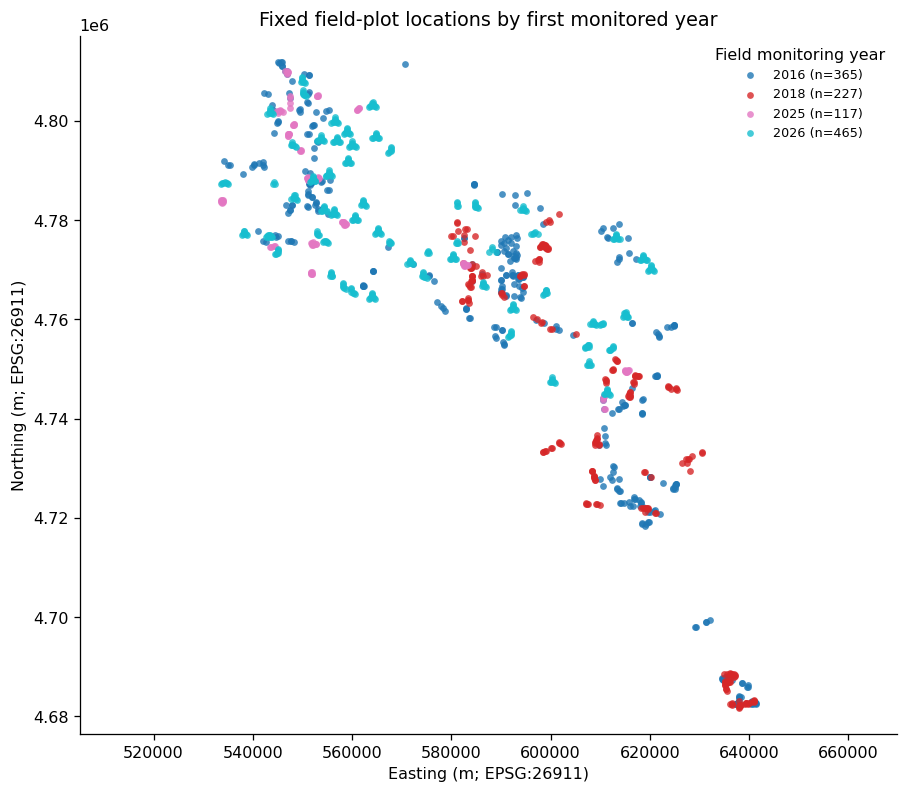

,first_field_year,n_sites,n_revisited,median_spectral_years
0,2016,365,0,11.0
1,2018,227,0,11.0
2,2025,117,0,11.0
3,2026,465,0,11.0


In [30]:
# One map point per unique coordinate site.
site_inventory = (wide.sort_values('field_year')
    .groupby('site_key', as_index=False)
    .agg(Easting=('Easting','first'), Northing=('Northing','first'),
         first_field_year=('field_year','min'),
         last_field_year=('field_year','max'),
         n_field_observations=('field_observation_key','nunique'),
         n_spectral_years=('spectral_year','nunique')))

fig, ax = plt.subplots(figsize=(8, 7))
years = sorted(site_inventory.first_field_year.unique())
cmap = plt.get_cmap('tab10' if len(years) <= 10 else 'turbo')
for i, y in enumerate(years):
    sub = site_inventory[site_inventory.first_field_year == y]
    ax.scatter(sub.Easting, sub.Northing, s=18, alpha=.8,
               label=f'{y} (n={len(sub)})', color=cmap(i / max(1, len(years)-1)),
               linewidths=0)
ax.set(xlabel='Easting (m; EPSG:26911)', ylabel='Northing (m; EPSG:26911)',
       title='Fixed field-plot locations by first monitored year')
ax.set_aspect('equal', adjustable='datalim')
ax.legend(title='Field monitoring year', fontsize=8, frameon=False,
          loc='best')
plt.tight_layout()
plt.show()

display(site_inventory.groupby('first_field_year',as_index=False).agg(
    n_sites=('site_key','size'),
    n_revisited=('n_field_observations',lambda x: int((x>1).sum())),
    median_spectral_years=('n_spectral_years','median')
))

## 3. Observation support

Each `nObs` counts valid daily images contributing to that pixel's monthly median; it is **not** the number of independent field samples. Review both the site-wide monthly counts and the fraction of sites with at least one observation, especially in November–December and the incomplete 2026 year.

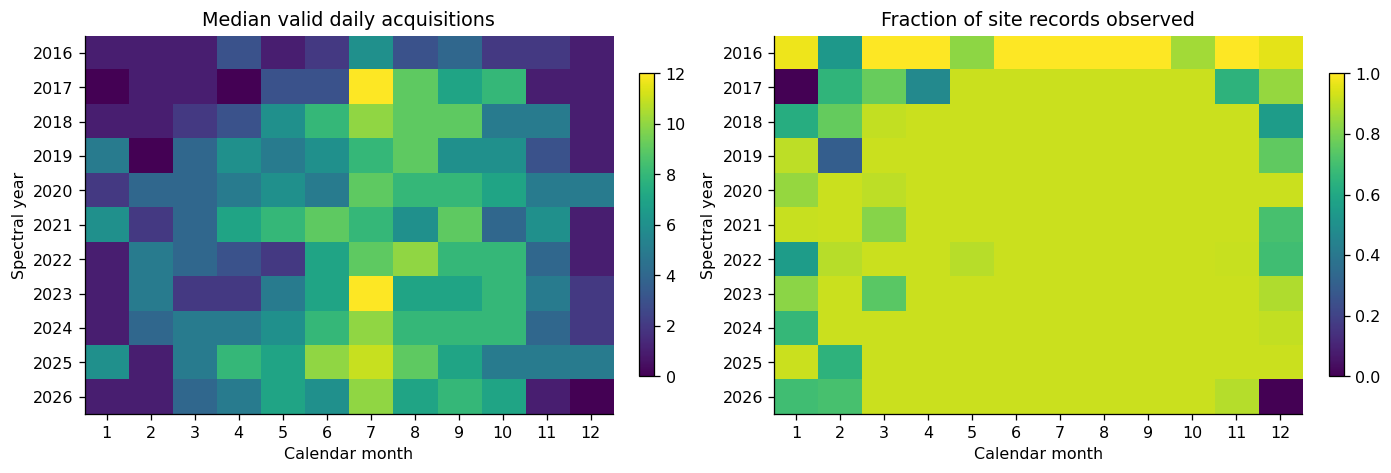

month,1,2,3,4,5,6,7,8,9,10,11,12
spectral_year,,,,,,,,,,,,
2016,1.0,1.0,1.0,3.0,1.0,2.0,6.0,3.0,4.0,2.0,2.0,1.0
2017,0.0,1.0,1.0,0.0,3.0,3.0,12.0,9.0,7.0,8.0,1.0,1.0
2018,1.0,1.0,2.0,3.0,6.0,8.0,10.0,9.0,9.0,5.0,5.0,1.0
2019,5.0,0.0,4.0,6.0,5.0,6.0,8.0,9.0,6.0,6.0,3.0,1.0
2020,2.0,4.0,4.0,5.0,6.0,5.0,9.0,8.0,8.0,7.0,5.0,5.0
2021,6.0,2.0,4.0,7.0,8.0,9.0,8.0,6.0,9.0,4.0,6.0,1.0
2022,1.0,5.0,4.0,3.0,2.0,7.0,9.0,10.0,8.0,8.0,4.0,1.0
2023,1.0,5.0,2.0,2.0,5.0,7.0,12.0,7.0,7.0,8.0,5.0,2.0
2024,1.0,4.0,5.0,5.0,6.0,8.0,10.0,8.0,8.0,8.0,4.0,2.0


In [31]:
coverage = (long[long.variable=='NDVI']
 .groupby(['spectral_year','month'],as_index=False)
 .agg(median_nObs=('nObs','median'),
      mean_nObs=('nObs','mean'),
      fraction_observed=('nObs', lambda s: float((s>=MIN_NOBS).mean()))))

fig, axs = plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,col,title in zip(axs,['median_nObs','fraction_observed'],
                        ['Median valid daily acquisitions', 'Fraction of site records observed']):
    matrix = coverage.pivot(index='spectral_year',columns='month',values=col)
    im = ax.imshow(matrix.values,aspect='auto',interpolation='none',cmap='viridis',
                   vmin=0,vmax=(1 if col=='fraction_observed' else None))
    ax.set_xticks(range(12),range(1,13));ax.set_yticks(range(len(matrix.index)),matrix.index)
    ax.set(xlabel='Calendar month',ylabel='Spectral year',title=title)
    fig.colorbar(im,ax=ax,shrink=.8)
plt.show()

display(coverage.pivot(index='spectral_year',columns='month',values='median_nObs').round(1))

## 4. Site–spectral-year summaries

We calculate each site's **seasonal average of observed monthly medians** and its **annual median of monthly medians** for each spectral variable. These are *summary statistics of monthly composites*, not direct medians of every satellite acquisition. Missing months are omitted; `n_months` indicates temporal support. Seasonal definitions are fixed calendar windows (DJF/MAM/JJA/SON), not inferred phenophases. Winter is assigned to the **same calendar year**, so December is not grouped with the following January/February.

In [32]:
group_cols = ['site_key','field_observation_key','plot_id','field_year',
              'spectral_year','Easting','Northing','variable']
annual = (long.groupby(group_cols,as_index=False,dropna=False)
          .agg(annual_median_of_monthlies=('median','median'),
               n_months=('median','count'),
               n_total_daily_obs=('nObs','sum')))
seasonal = (long.groupby(group_cols + ['season'],as_index=False,dropna=False)
            .agg(seasonal_mean_of_monthlies=('median','mean'),
                 n_months=('median','count'),
                 n_total_daily_obs=('nObs','sum')))

# Clean, wide site–spectral-year summary for GIS and modeling notebooks.
annual_wide = annual.pivot(index=group_cols[:-1], columns='variable',
                           values='annual_median_of_monthlies').reset_index()
annual_wide.columns.name = None
annual_wide = annual_wide.rename(columns={v:f'annual_{v}' for v in VARIABLES})

seasonal_wide = seasonal.pivot(
    index=group_cols[:-1],columns=['season','variable'],
    values='seasonal_mean_of_monthlies')
seasonal_wide.columns = [f'{season}_{var}' for season,var in seasonal_wide.columns]
seasonal_wide = seasonal_wide.reset_index()

summary = annual_wide.merge(seasonal_wide, on=group_cols[:-1],validate='one_to_one')
obs_counts = annual[annual.variable=='NDVI'][group_cols[:-1]+['n_months','n_total_daily_obs']]
summary = summary.merge(obs_counts,on=group_cols[:-1],validate='one_to_one')
summary['is_field_year'] = summary.field_year.eq(summary.spectral_year)

# Avoid interpreting a non-monitored spectral year as a field survey.
summary.to_csv(OUTPUT_DIR/'NCA_site_spectral_year_summary.csv',index=False)
coverage.to_csv(OUTPUT_DIR/'NCA_monthly_observation_coverage.csv',index=False)
site_inventory.to_csv(OUTPUT_DIR/'NCA_site_inventory.csv',index=False)
print(f'Saved summaries to: {OUTPUT_DIR.resolve()}')
display(summary.head())

Saved summaries to: C:\Users\scottfordham\BOP_OCTC\Python\BOP Datapull\Medians\outputs\monthly_medians


,site_key,field_observation_key,plot_id,field_year,spectral_year,Easting,Northing,annual_B11,annual_B12,annual_B2,...,spring_NDRE,summer_NDRE,winter_NDRE,autumn_NDVI,spring_NDVI,summer_NDVI,winter_NDVI,n_months,n_total_daily_obs,is_field_year
0,533507.00::4783789.94,NaN,<NA>,2025,2016,533507.000321,4.783790e+06,0.364925,0.32390,0.187800,...,0.025432,0.011674,0.026293,0.070291,0.130591,0.074673,0.080662,10,26.0,False
1,533507.00::4783789.94,NaN,<NA>,2025,2017,533507.000321,4.783790e+06,0.276700,0.24220,0.093600,...,0.025925,0.038113,0.051477,0.160529,0.164588,0.164626,0.151157,9,50.0,False
2,533507.00::4783789.94,NaN,<NA>,2025,2018,533507.000321,4.783790e+06,0.276100,0.23985,0.100000,...,0.038965,0.026242,0.048838,0.123911,0.174365,0.116804,0.160274,11,61.0,False
3,533507.00::4783789.94,NaN,<NA>,2025,2019,533507.000321,4.783790e+06,0.275350,0.23700,0.094900,...,0.027305,0.024872,0.049532,0.144626,0.178676,0.148169,0.133422,11,56.0,False
4,533507.00::4783789.94,NaN,<NA>,2025,2020,533507.000321,4.783790e+06,0.272700,0.23420,0.097375,...,0.041126,0.029924,0.045305,0.144609,0.178703,0.154153,0.143647,12,79.0,False


## 5. Longitudinal trajectories at a selected site

The field collection year is marked with a vertical dashed line. If coordinates were surveyed in multiple years, all observed field years at the site are marked. This graph shows **spectral evolution only**; there are no interpolated or assumed field measurements. Select the site using `SITE_INDEX` from the displayed inventory. The plot works without `ipywidgets`.

,SITE_INDEX,site_key,first_field_year,n_field_observations,n_spectral_years,Easting,Northing
0,0,534286.32::4791893.43,2016,0,11,534286.324549,4.791893e+06
1,1,534956.44::4791064.46,2016,0,11,534956.444108,4.791064e+06
2,2,535341.14::4791052.05,2016,0,11,535341.142373,4.791052e+06
3,3,538024.10::4789204.01,2016,0,11,538024.102534,4.789204e+06
4,4,539909.87::4790678.77,2016,0,11,539909.868613,4.790679e+06
5,5,540148.13::4791173.67,2016,0,11,540148.133345,4.791174e+06
6,6,540253.37::4791293.30,2016,0,11,540253.366935,4.791293e+06
7,7,541108.14::4777715.19,2016,0,10,541108.141661,4.777715e+06
8,8,541221.81::4791506.74,2016,0,11,541221.813794,4.791507e+06
9,9,541954.97::4791726.14,2016,0,11,541954.974230,4.791726e+06


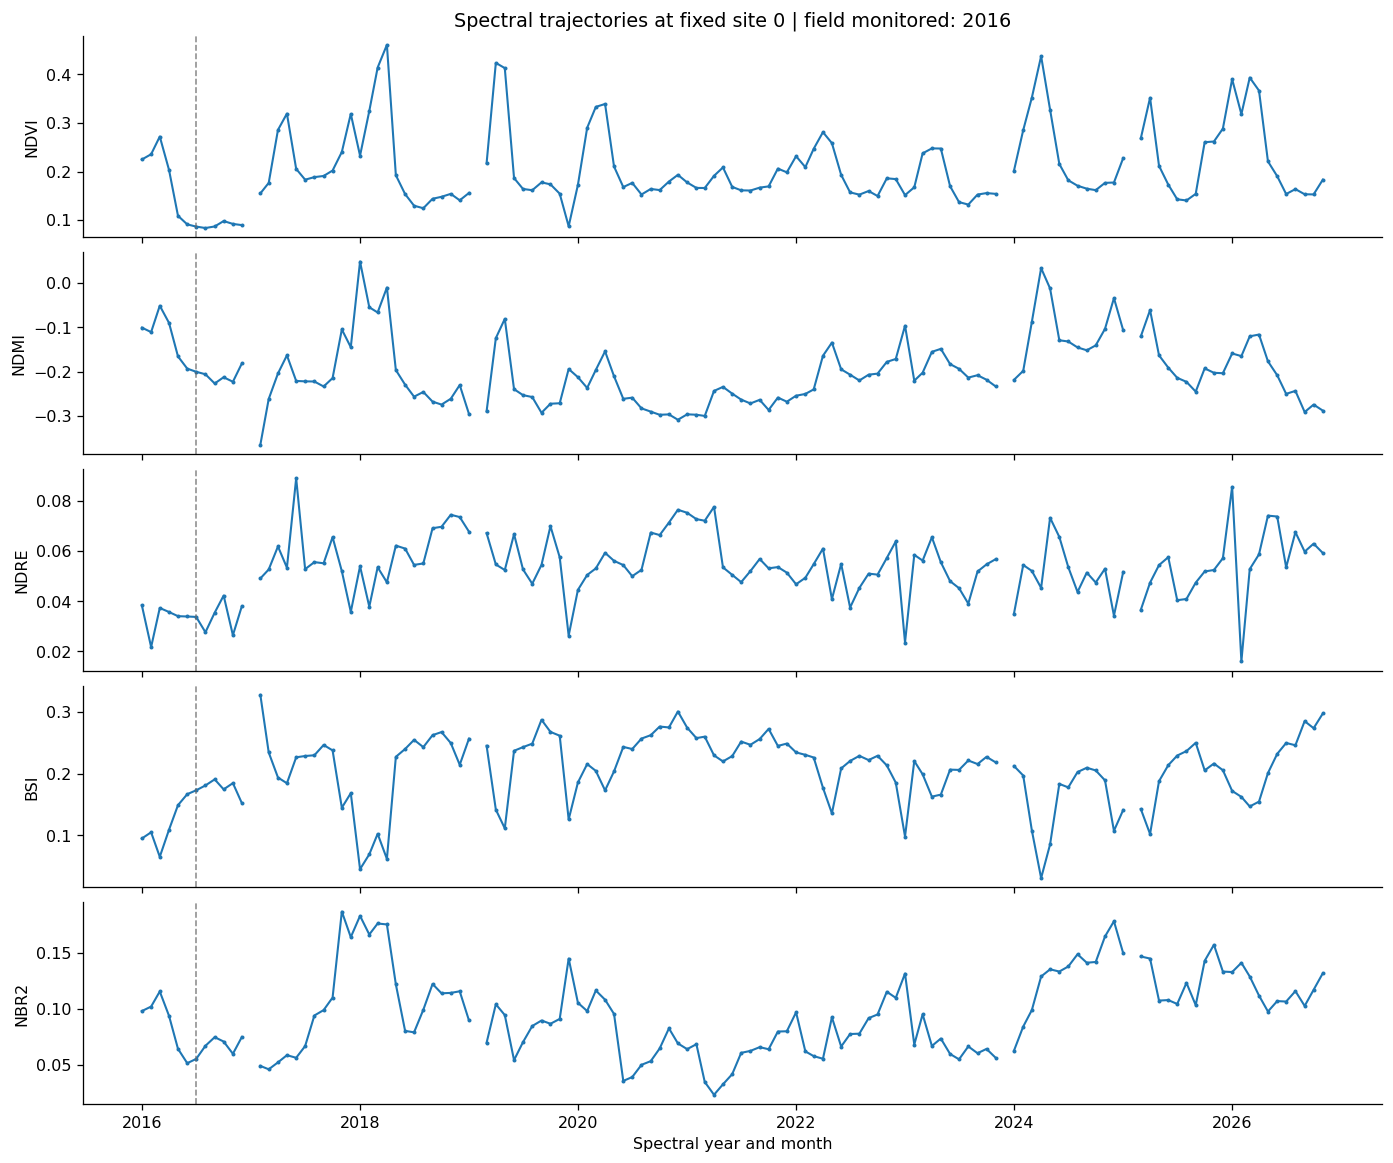

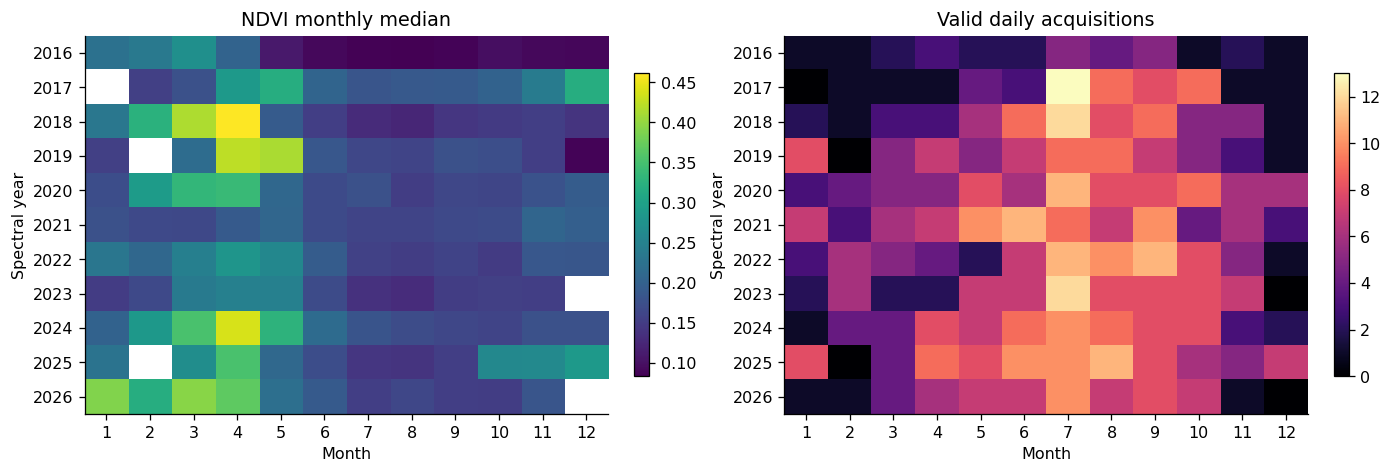

In [33]:
# Inspect/select a site. Sorted by first monitoring year, then location.
site_choices = site_inventory.sort_values(
    ['first_field_year','Easting','Northing']).reset_index(drop=True)
site_choices.insert(0,'SITE_INDEX',np.arange(len(site_choices)))
display(site_choices[['SITE_INDEX','site_key','first_field_year',
                      'n_field_observations','n_spectral_years','Easting','Northing']].head(25))

SITE_INDEX = 0
SITE_VARIABLES = ['NDVI','NDMI','NDRE','BSI','NBR2']

if not 0 <= SITE_INDEX < len(site_choices):
    raise IndexError('SITE_INDEX outside site inventory')
selected_site = site_choices.loc[SITE_INDEX,'site_key']
selected = long[(long.site_key==selected_site) & (long.variable.isin(SITE_VARIABLES))]

# Multiple field observations at same coordinates duplicate spectral values;
# use one record per coordinate × spectral year × month × variable.
selected = selected.drop_duplicates(['site_key','spectral_year','month','variable'])
monitored_years = sorted(wide.loc[wide.site_key==selected_site,'field_year'].unique())
fig,axs=plt.subplots(len(SITE_VARIABLES),1,figsize=(12,10),sharex=True,layout='constrained')
for ax,var in zip(axs,SITE_VARIABLES):
    ss=selected[selected.variable==var].sort_values('month_date')
    # Gaps remain gaps when no valid monthly imagery is available.
    ax.plot(ss.month_date,ss['median'],marker='.',ms=3,lw=1.3)
    for fy in monitored_years:
        ax.axvline(pd.Timestamp(int(fy),7,1),ls='--',lw=1,color='0.4',alpha=.75)
    ax.set_ylabel(var)
axs[0].set_title(f'Spectral trajectories at fixed site {SITE_INDEX} | '
                 f'field monitored: {", ".join(map(str,monitored_years))}')
axs[-1].set_xlabel('Spectral year and month')
plt.show()

# Detailed year × month heatmaps for both values and acquisition counts.
DISPLAY_VARIABLE = 'NDVI'
fig, axs = plt.subplots(1,2,figsize=(12,4),layout='constrained')
ss = selected[selected.variable==DISPLAY_VARIABLE]
for ax,col,label,cmap in zip(axs,['median','nObs'],
                             [f'{DISPLAY_VARIABLE} monthly median','Valid daily acquisitions'],
                             ['viridis','magma']):
    matrix = ss.pivot(index='spectral_year',columns='month',values=col)
    im=ax.imshow(matrix.values,aspect='auto',interpolation='none',cmap=cmap)
    ax.set_xticks(range(12),range(1,13));ax.set_yticks(range(len(matrix)),matrix.index)
    ax.set(xlabel='Month',ylabel='Spectral year',title=label)
    fig.colorbar(im,ax=ax,shrink=.8)
plt.show()

## 6. Map apparent spectral change at the fixed sites

This map shows **change in a selected seasonal spectral index** between two spectral years—not a change in measured vegetation state. Sites must have at least one valid monthly observation in the relevant season in *both* years. Points with insufficient data are omitted from the change layer. Because observations are at fixed points, site identity is defined by exported coordinates rather than `PlotID` alone.

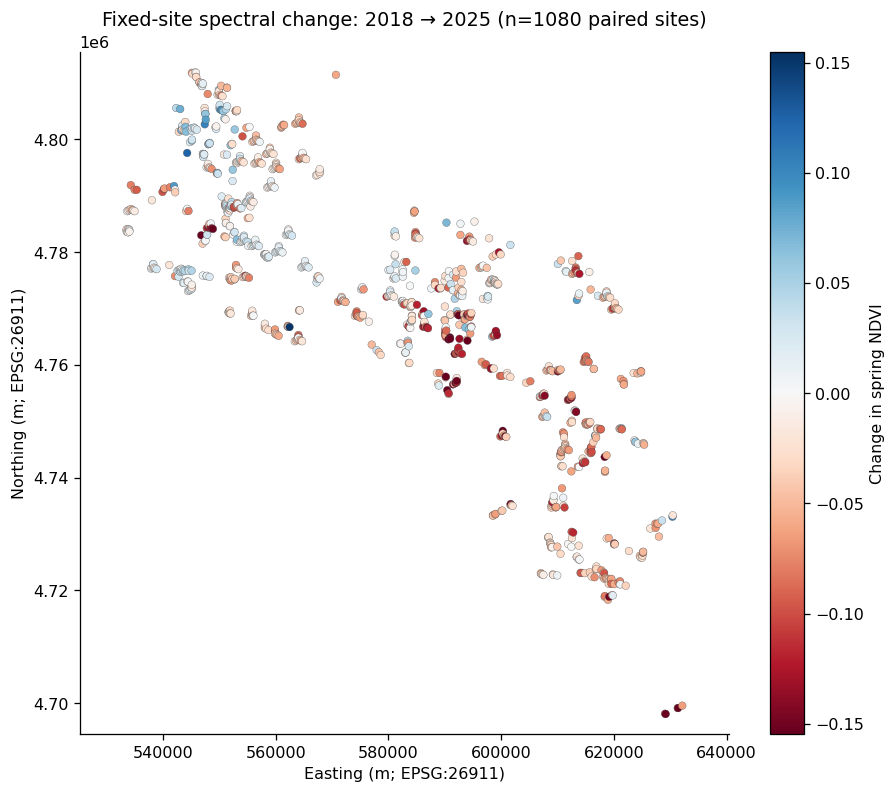

In [34]:
change = seasonal[
    (seasonal.variable==MAP_VARIABLE) &
    (seasonal.season==MAP_SEASON) &
    (seasonal.spectral_year.isin(CHANGE_YEARS)) &
    (seasonal.n_months>0)
].drop_duplicates(['site_key','spectral_year'])

change_wide = change.pivot(index='site_key',columns='spectral_year',
                           values='seasonal_mean_of_monthlies')
if all(y in change_wide.columns for y in CHANGE_YEARS):
    change_wide = change_wide.dropna(subset=list(CHANGE_YEARS)).copy()
    change_wide['delta'] = change_wide[CHANGE_YEARS[1]] - change_wide[CHANGE_YEARS[0]]
    change_map = site_inventory.merge(
        change_wide[['delta']].reset_index(),on='site_key',how='inner')
    fig,ax=plt.subplots(figsize=(8,7))
    absmax = max(float(change_map.delta.abs().quantile(.98)) if len(change_map) else 0,1e-6)
    im=ax.scatter(change_map.Easting,change_map.Northing,
                  c=change_map.delta,cmap='RdBu',vmin=-absmax,vmax=absmax,
                  s=23,linewidths=.2,edgecolors='0.3')
    fig.colorbar(im,ax=ax,label=f'Change in {MAP_SEASON} {MAP_VARIABLE}')
    ax.set_aspect('equal',adjustable='datalim')
    ax.set(xlabel='Easting (m; EPSG:26911)',ylabel='Northing (m; EPSG:26911)',
           title=f'Fixed-site spectral change: {CHANGE_YEARS[0]} → {CHANGE_YEARS[1]} '
                 f'(n={len(change_map)} paired sites)')
    plt.tight_layout();plt.show()
    change_map.to_csv(OUTPUT_DIR/'NCA_site_seasonal_change_map.csv',index=False)
else:
    print(f'Change map requires both {CHANGE_YEARS}; available years: '
          f'{sorted(change_wide.columns.tolist())}')

## 7. What to interpret—and what not to infer

**Useful questions this notebook can address:**

1. Which months provide consistent observations at individual pixels, and do those months vary geographically?
2. Which field locations show large interannual departures in spring or summer NDVI, NDMI, NDRE, BSI, or NBR2?
3. Are the apparent longitudinal changes spatially clustered, or do nearby plots move similarly?
4. Are changes dominated by low-observation months (a measurement-support question) rather than consistent spectral trajectories?
5. Do sites monitored in different field campaigns occupy different regions of the NCA's seasonal spectral feature space?

**Inference boundaries:** The same spectral pixel in multiple years is not independent field evidence. A satellite time series at a fixed coordinate cannot establish vegetation cover or state transitions between field visits without validated prediction and uncertainty. The year-2026 data are incomplete until the calendar year and ingestion are complete. Seasonal averages of monthly medians differ from directly composited seasonal medians. Band B5/B6/B7/B8A/B11/B12 have coarser native resolution than the 10 m sampling grid; exporting at 10 m does not create native 10 m information.

**Suggested next notebook:** compare complete monthly medians against phase-aware K2 harmonics for the *same contemporaneously monitored plot-years*, with held-out spatial groups and missingness controlled. The present notebook deliberately performs descriptive analysis, not state retrieval.

In [43]:

# ============================================================
# SEASONAL SITE-YEAR DATASET
# One row per unique coordinate site and spectral year
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANALYSIS_YEARS = list(range(2016, 2026))

SEASONS = {
    "Spring": [3, 4, 5],
    "Summer": [6, 7, 8],
    "Autumn": [9, 10, 11],
}

ANALYSIS_VARS = [
    "NDVI", "NDMI", "NDRE", "BSI", "NBR2"
]

MIN_MONTHLY_NOBS = 2
MIN_VALID_MONTHS = 2

# Repeated field observations at the same coordinates are not
# independent spectral sites.
site_year = (
    wide.loc[
        wide["spectral_year"].isin(ANALYSIS_YEARS)
    ]
    .groupby(
        ["site_key", "spectral_year"],
        as_index=False
    )
    .first()
)

# Build seasonal summaries from observed monthly medians.
for season, months in SEASONS.items():

    valid_cols = [
        f"m{m:02d}_nObs" for m in months
    ]

    valid_months = (
        site_year[valid_cols]
        .ge(MIN_MONTHLY_NOBS)
    )

    site_year[f"{season}_valid_months"] = (
        valid_months.sum(axis=1)
    )

    for variable in ANALYSIS_VARS:

        value_cols = [
            f"m{m:02d}_{variable}"
            for m in months
        ]

        values = site_year[value_cols].copy()

        values.columns = valid_cols
        values = values.where(valid_months)

        seasonal_mean = values.mean(axis=1)

        site_year[f"{season}_{variable}"] = (
            seasonal_mean.where(
                values.notna().sum(axis=1)
                >= MIN_VALID_MONTHS
            )
        )

print(
    f"{site_year.site_key.nunique():,} unique sites | "
    f"{len(site_year):,} site-year records"
)

display(
    site_year.groupby("spectral_year").agg(
        sites=("site_key", "nunique"),
        valid_spring_ndvi=("Spring_NDVI", "count"),
        valid_summer_ndvi=("Summer_NDVI", "count"),
        valid_autumn_ndvi=("Autumn_NDVI", "count")
    )
)


1,174 unique sites | 11,506 site-year records


C:\Users\scottfordham\AppData\Local\Temp\ipykernel_29992\2636788231.py:35: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()
C:\Users\scottfordham\AppData\Local\Temp\ipykernel_29992\2636788231.py:35: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


,sites,valid_spring_ndvi,valid_summer_ndvi,valid_autumn_ndvi
spectral_year,,,,
2016,940,352,940,770
2017,1174,158,1080,1080
2018,1174,1080,1080,1080
2019,1174,1080,1080,1080
2020,1174,1080,1080,1080
2021,1174,1080,1080,1080
2022,1174,1076,1080,1080
2023,1174,988,1080,1080
2024,1174,1080,1080,1080


Metric: Spring_NDVI
Sites: 1,080
Between-site variance: 0.004061
Mean within-site variance: 0.002591
Descriptive persistence ratio: 0.611


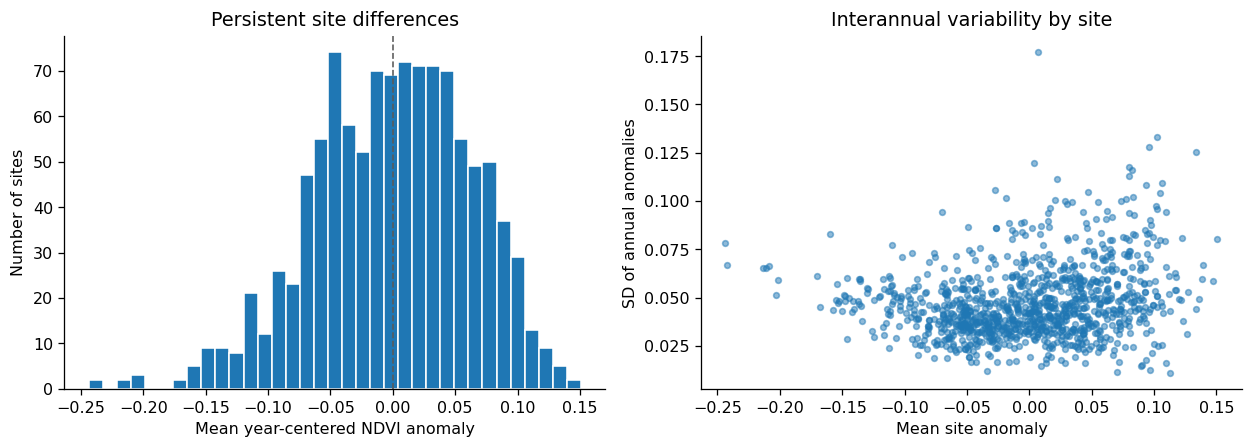

In [44]:

# ============================================================
# SITE PERSISTENCE VS INTERANNUAL VARIATION
# Descriptive decomposition of year-centered anomalies
# ============================================================

SEASON = "Spring"
VARIABLE = "NDVI"
MIN_SITE_YEARS = 6

metric = f"{SEASON}_{VARIABLE}"

d = site_year[
    ["site_key", "spectral_year", metric]
].dropna().copy()

# Restrict to sites observed in enough spectral years.
eligible = (
    d.groupby("site_key")["spectral_year"]
    .nunique()
)

eligible_sites = eligible[
    eligible >= MIN_SITE_YEARS
].index

d = d[d["site_key"].isin(eligible_sites)].copy()

if d.empty:
    raise ValueError("No sites meet the temporal coverage requirement.")

# A site's anomaly relative to the landscape in that year.
d["year_mean"] = (
    d.groupby("spectral_year")[metric]
    .transform("mean")
)

d["anomaly"] = d[metric] - d["year_mean"]

# Persistent spatial component: average anomaly by site.
site_stats = (
    d.groupby("site_key")
    .agg(
        mean_anomaly=("anomaly", "mean"),
        temporal_sd=("anomaly", "std"),
        n_years=("spectral_year", "nunique")
    )
)

# Descriptive comparison (not an additive variance-component model).
between_site_variance = (
    site_stats["mean_anomaly"].var()
)

within_site_variance = (
    site_stats["temporal_sd"].pow(2).mean()
)

persistence_ratio = (
    between_site_variance
    / (between_site_variance + within_site_variance)
)

print(f"Metric: {metric}")
print(f"Sites: {len(site_stats):,}")
print(f"Between-site variance: {between_site_variance:.6f}")
print(f"Mean within-site variance: {within_site_variance:.6f}")
print(f"Descriptive persistence ratio: {persistence_ratio:.3f}")

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4)
)

axes[0].hist(
    site_stats["mean_anomaly"],
    bins=35,
    edgecolor="white"
)
axes[0].axvline(0, color="0.35", ls="--", lw=1)
axes[0].set_xlabel(f"Mean year-centered {VARIABLE} anomaly")
axes[0].set_ylabel("Number of sites")
axes[0].set_title("Persistent site differences")

axes[1].scatter(
    site_stats["mean_anomaly"],
    site_stats["temporal_sd"],
    s=13,
    alpha=0.5
)
axes[1].set_xlabel("Mean site anomaly")
axes[1].set_ylabel("SD of annual anomalies")
axes[1].set_title("Interannual variability by site")

plt.tight_layout()
plt.show()


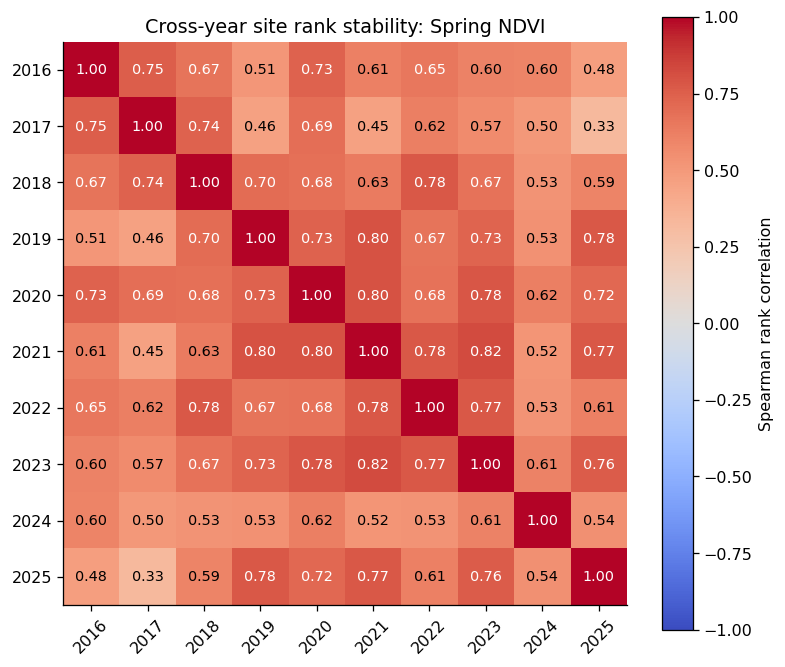

Mean pairwise Spearman rho: 0.647
Median pairwise Spearman rho: 0.666
Range: 0.327 to 0.824

Paired sites per comparison:


spectral_year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
spectral_year,,,,,,,,,,
2016,352,76,352,352,352,352,349,352,352,352
2017,76,158,158,158,158,158,158,158,158,158
2018,352,158,1080,1080,1080,1080,1076,988,1080,1080
2019,352,158,1080,1080,1080,1080,1076,988,1080,1080
2020,352,158,1080,1080,1080,1080,1076,988,1080,1080
2021,352,158,1080,1080,1080,1080,1076,988,1080,1080
2022,349,158,1076,1076,1076,1076,1076,984,1076,1076
2023,352,158,988,988,988,988,984,988,988,988
2024,352,158,1080,1080,1080,1080,1076,988,1080,1080


In [45]:

# ============================================================
# CROSS-YEAR SPECTRAL RANK STABILITY
# Pairwise Spearman correlations among fixed sites
# ============================================================

SEASON = "Spring"
VARIABLE = "NDVI"

metric = f"{SEASON}_{VARIABLE}"

matrix = site_year.pivot(
    index="site_key",
    columns="spectral_year",
    values=metric
).reindex(columns=ANALYSIS_YEARS)

# Pairwise-complete Spearman correlations.
rank_corr = matrix.corr(method="spearman")

# Number of paired sites supporting each comparison.
years = matrix.columns

pair_counts = pd.DataFrame(
    index=years,
    columns=years,
    dtype=int
)

for y1 in years:
    for y2 in years:
        pair_counts.loc[y1, y2] = (
            matrix[[y1, y2]]
            .notna()
            .all(axis=1)
            .sum()
        )

# Display correlations.
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    rank_corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    range(len(years)),
    years,
    rotation=45
)
ax.set_yticks(
    range(len(years)),
    years
)

for i in range(len(years)):
    for j in range(len(years)):

        value = rank_corr.iloc[i, j]

        if np.isfinite(value):
            ax.text(
                j, i, f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color=(
                    "white"
                    if abs(value) > 0.65
                    else "black"
                )
            )

fig.colorbar(
    im, ax=ax,
    label="Spearman rank correlation"
)

ax.set_title(
    f"Cross-year site rank stability: {SEASON} {VARIABLE}"
)

plt.tight_layout()
plt.show()

# Summarize off-diagonal correlations.
upper = np.triu(
    np.ones(rank_corr.shape, dtype=bool),
    k=1
)

values = rank_corr.to_numpy()[upper]
values = values[np.isfinite(values)]

print(f"Mean pairwise Spearman rho: {values.mean():.3f}")
print(f"Median pairwise Spearman rho: {np.median(values):.3f}")
print(f"Range: {values.min():.3f} to {values.max():.3f}")

print("\nPaired sites per comparison:")
display(pair_counts.astype(int))
